In [4]:
# ============================================================
# Step 1: Load and Explore the Data
# ============================================================

# Import required libraries
import pandas as pd
import matplotlib.pyplot as plt

In [5]:
# Load the Telco Customer Churn dataset
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [6]:
# Display the first five rows
print("First five rows:")
display(df.head())

First five rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [7]:
# Check the dataset shape
print("Dataset shape:")
print(df.shape)

Dataset shape:
(7043, 21)


In [8]:
# Display column names
print("\nColumn names:")
print(df.columns.tolist())


Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [9]:
# Display data types and non-null counts
print("\nDataset information:")
df.info()


Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null

In [10]:
# Check for missing values
print("\nMissing values:")
display(df.isna().sum())


Missing values:


customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [11]:
# Check for blank values
print("\nBlank values:")
blank_values = df.select_dtypes(include="object").apply(
    lambda column: column.str.strip().eq("").sum()
)
display(blank_values[blank_values > 0])


Blank values:


/var/folders/r4/b92fgm8557qf_dj7jydv2r3c0000gn/T/ipykernel_12917/2684216454.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  blank_values = df.select_dtypes(include="object").apply(


TotalCharges    11
dtype: int64

In [12]:
# Display summary statistics
print("\nSummary statistics:")
display(df.describe())


Summary statistics:


,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [13]:
# Check the target distribution
print("\nChurn distribution:")
display(df["Churn"].value_counts())


Churn distribution:


Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [14]:
# Display churn percentages
print("\nChurn percentages:")
display(df["Churn"].value_counts(normalize=True).mul(100).round(2))


Churn percentages:


Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

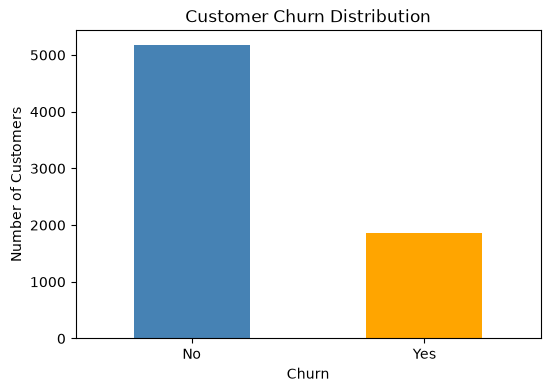

In [15]:
# ============================================================
# Visualize Key Features
# ============================================================

# Visualize customer churn
df["Churn"].value_counts().plot(
    kind="bar",
    figsize=(6, 4),
    color=["steelblue", "orange"],
    title="Customer Churn Distribution"
)

plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.show()

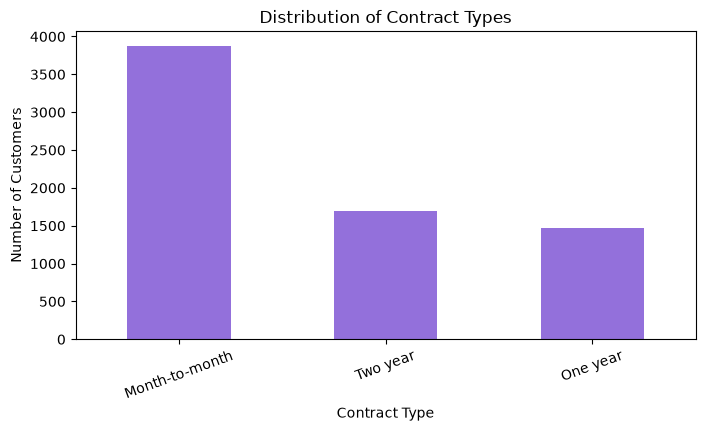

In [16]:
# Visualize contract types
df["Contract"].value_counts().plot(
    kind="bar",
    figsize=(8, 4),
    color="mediumpurple",
    title="Distribution of Contract Types"
)

plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=20)
plt.show()

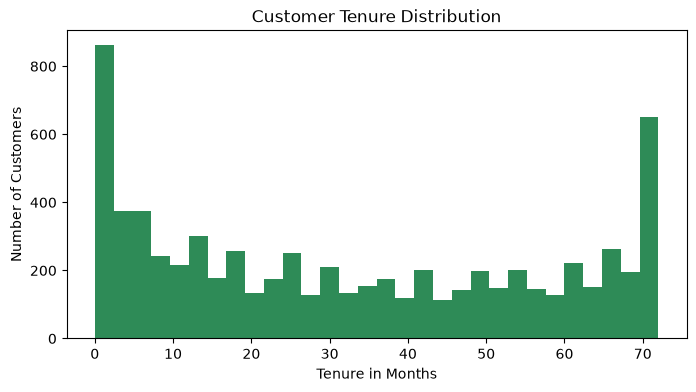

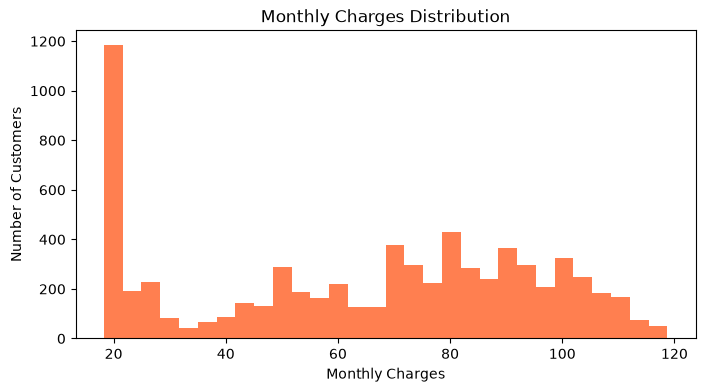

In [17]:
# Visualize customer tenure
df["tenure"].plot(
    kind="hist",
    bins=30,
    figsize=(8, 4),
    color="seagreen",
    title="Customer Tenure Distribution"
)

plt.xlabel("Tenure in Months")
plt.ylabel("Number of Customers")
plt.show()


# Visualize monthly charges
df["MonthlyCharges"].plot(
    kind="hist",
    bins=30,
    figsize=(8, 4),
    color="coral",
    title="Monthly Charges Distribution"
)

plt.xlabel("Monthly Charges")
plt.ylabel("Number of Customers")
plt.show()

In [18]:
# ============================================================
# Step 2: Data Preprocessing
# ============================================================

# Create a copy so the original dataset remains unchanged
df_processed = df.copy()


# Remove unnecessary spaces from text columns
text_columns = df_processed.select_dtypes(include="object").columns

for column in text_columns:
    df_processed[column] = df_processed[column].str.strip()


# Convert TotalCharges from text to numeric
# Invalid or blank values will become NaN
df_processed["TotalCharges"] = pd.to_numeric(
    df_processed["TotalCharges"],
    errors="coerce"
)


# Check missing values after conversion
print("Missing values before handling:")
display(df_processed.isna().sum()[df_processed.isna().sum() > 0])

Missing values before handling:


/var/folders/r4/b92fgm8557qf_dj7jydv2r3c0000gn/T/ipykernel_12917/2379682241.py:10: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_columns = df_processed.select_dtypes(include="object").columns


TotalCharges    11
dtype: int64

In [19]:
# Fill missing numerical values with the median
numeric_columns = df_processed.select_dtypes(include=["int64", "float64"]).columns

for column in numeric_columns:
    df_processed[column] = df_processed[column].fillna(
        df_processed[column].median()
    )


# Fill missing categorical values with the most common value
categorical_columns = df_processed.select_dtypes(include="object").columns

for column in categorical_columns:
    df_processed[column] = df_processed[column].fillna(
        df_processed[column].mode()[0]
    )


# Confirm that no missing values remain
print("Missing values after handling:")
display(df_processed.isna().sum()[df_processed.isna().sum() > 0])

print("Total missing values:", df_processed.isna().sum().sum())

Missing values after handling:


/var/folders/r4/b92fgm8557qf_dj7jydv2r3c0000gn/T/ipykernel_12917/829560197.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df_processed.select_dtypes(include="object").columns


Series([], dtype: int64)

Total missing values: 0


In [20]:
# Convert the target variable from Yes/No to 1/0
y = df_processed["Churn"].map({
    "No": 0,
    "Yes": 1
})


# Select the input features
# customerID is removed because it is only an identifier
X = df_processed.drop(
    columns=["Churn", "customerID"]
)


# Display the selected features
print("Selected features:")
print(X.columns.tolist())

Selected features:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']


In [21]:
# Convert categorical variables into numerical dummy variables
# drop_first=True prevents duplicate information
X = pd.get_dummies(
    X,
    drop_first=True,
    dtype=int
)


# Check the processed feature data
print("Processed feature shape:", X.shape)

print("\nFirst five rows of processed features:")
display(X.head())


# Check the target data
print("\nTarget values:")
display(y.value_counts())

Processed feature shape: (7043, 31)

First five rows of processed features:


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,1,0,0,1,0,...,0,0,0,0,0,0,1,0,1,0
1,0,34,56.95,1889.50,1,0,0,1,0,0,...,0,0,0,0,1,0,0,0,0,1
2,0,2,53.85,108.15,1,0,0,1,0,0,...,0,0,0,0,0,0,1,0,0,1
3,0,45,42.30,1840.75,1,0,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
4,0,2,70.70,151.65,0,0,0,1,0,0,...,0,0,0,0,0,0,1,0,1,0



Target values:


Churn
0    5174
1    1869
Name: count, dtype: int64

In [22]:
# Convert categorical variables into numerical dummy variables
# drop_first=True prevents duplicate information
X = pd.get_dummies(
    X,
    drop_first=True,
    dtype=int
)


# Check the processed feature data
print("Processed feature shape:", X.shape)

print("\nFirst five rows of processed features:")
display(X.head())


# Check the target data
print("\nTarget values:")
display(y.value_counts())

Processed feature shape: (7043, 31)

First five rows of processed features:


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,1,0,0,1,0,...,0,0,0,0,0,0,1,0,1,0
1,0,34,56.95,1889.50,1,0,0,1,0,0,...,0,0,0,0,1,0,0,0,0,1
2,0,2,53.85,108.15,1,0,0,1,0,0,...,0,0,0,0,0,0,1,0,0,1
3,0,45,42.30,1840.75,1,0,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
4,0,2,70.70,151.65,0,0,0,1,0,0,...,0,0,0,0,0,0,1,0,1,0



Target values:


Churn
0    5174
1    1869
Name: count, dtype: int64

In [23]:
# Confirm that all feature columns are numeric
print("Are all features numeric?")
print(X.dtypes.value_counts())


# Confirm that the target contains only 0 and 1
print("\nUnique target values:")
print(y.unique())


# Confirm there are no missing values
print("\nMissing values in X:", X.isna().sum().sum())
print("Missing values in y:", y.isna().sum())

Are all features numeric?
int64      29
float64     2
Name: count, dtype: int64

Unique target values:
[0 1]

Missing values in X: 0
Missing values in y: 0


In [24]:
# ============================================================
# Step 3: Split the Data
# ============================================================

# Import the train_test_split function
from sklearn.model_selection import train_test_split


# Split the data into training and testing sets
# 80% of the data is used for training
# 20% of the data is used for testing
# stratify=y keeps the same churn proportions in both sets
# random_state=42 makes the split reproducible
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)


# Display the shape of each dataset
print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)


# Check the churn distribution in the training set
print("\nTraining target distribution:")
display(y_train.value_counts(normalize=True).mul(100).round(2))


# Check the churn distribution in the testing set
print("\nTesting target distribution:")
display(y_test.value_counts(normalize=True).mul(100).round(2))

Training features shape: (5634, 31)
Testing features shape: (1409, 31)
Training target shape: (5634,)
Testing target shape: (1409,)

Training target distribution:


Churn
0    73.46
1    26.54
Name: proportion, dtype: float64


Testing target distribution:


Churn
0    73.46
1    26.54
Name: proportion, dtype: float64

In [25]:
# ============================================================
# Step 4: Train a KNN Model
# ============================================================

# Import the required tools
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier


# Create a scaler
scaler = StandardScaler()


# Fit the scaler only on the training data
# This prevents information from the test set leaking into the model
X_train_scaled = scaler.fit_transform(X_train)


# Use the same scaler to transform the test data
X_test_scaled = scaler.transform(X_test)


# Create the KNN classifier with 5 neighbors
knn_model = KNeighborsClassifier(
    n_neighbors=5
)


# Train the KNN model
knn_model.fit(X_train_scaled, y_train)


print("KNN model trained successfully.")
print("Number of neighbors:", knn_model.n_neighbors)

KNN model trained successfully.
Number of neighbors: 5


In [26]:
# ============================================================
# Step 5: Make Predictions and Evaluate the KNN Model
# ============================================================

# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report
)


# Make predictions on the scaled test data
y_pred = knn_model.predict(X_test_scaled)


# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)


# Display the evaluation metrics
print("Model Evaluation Results")
print("------------------------")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")

Model Evaluation Results
------------------------
Accuracy:  0.7473
Precision: 0.5253
Recall:    0.5000


Confusion matrix:
[[866 169]
 [187 187]]


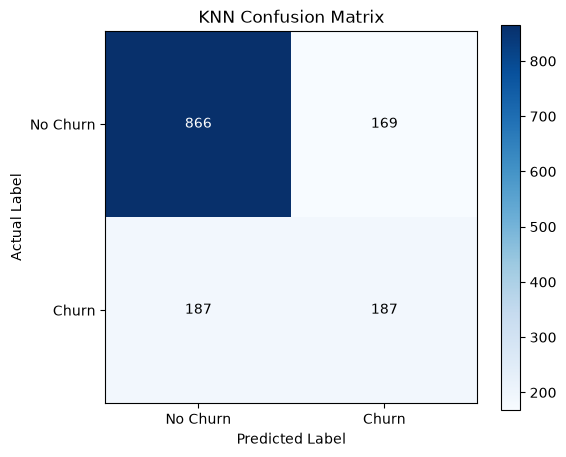

In [27]:
# Create the confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion matrix:")
print(cm)


# Display the confusion matrix as a chart
plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap="Blues")

plt.title("KNN Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.xticks([0, 1], ["No Churn", "Churn"])
plt.yticks([0, 1], ["No Churn", "Churn"])

# Add the values to the chart
for row in range(2):
    for column in range(2):
        plt.text(
            column,
            row,
            cm[row, column],
            ha="center",
            va="center",
            color="white" if cm[row, column] > cm.max() / 2 else "black"
        )

plt.colorbar()
plt.show()

In [28]:
# Generate a detailed classification report
print("Classification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["No Churn", "Churn"],
        zero_division=0
    )
)

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.82      0.84      0.83      1035
       Churn       0.53      0.50      0.51       374

    accuracy                           0.75      1409
   macro avg       0.67      0.67      0.67      1409
weighted avg       0.74      0.75      0.75      1409



In [29]:
# ============================================================
# Step 6: Experiment with Different K Values
# ============================================================

# Define the K values to test
k_values = [1, 3, 5, 7, 9, 11, 15]

# Store the results for each K value
results = []


# Train and evaluate a KNN model for each K value
for k in k_values:
    
    # Create the KNN model
    model = KNeighborsClassifier(n_neighbors=k)
    
    # Train the model using the scaled training data
    model.fit(X_train_scaled, y_train)
    
    # Make predictions on the scaled test data
    predictions = model.predict(X_test_scaled)
    
    # Calculate evaluation metrics
    model_accuracy = accuracy_score(y_test, predictions)
    model_precision = precision_score(
        y_test,
        predictions,
        zero_division=0
    )
    model_recall = recall_score(
        y_test,
        predictions,
        zero_division=0
    )
    
    # Store the results
    results.append({
        "K": k,
        "Accuracy": model_accuracy,
        "Precision": model_precision,
        "Recall": model_recall
    })


# Convert the results into a DataFrame
results_df = pd.DataFrame(results)

# Display the comparison table
print("KNN Model Performance Comparison:")
display(results_df.round(4))

KNN Model Performance Comparison:


,K,Accuracy,Precision,Recall
0,1,0.7161,0.4667,0.4866
1,3,0.7438,0.5177,0.5080
2,5,0.7473,0.5253,0.5000
3,7,0.7594,0.5499,0.5160
4,9,0.7693,0.5679,0.5481
5,11,0.7736,0.5770,0.5508
6,15,0.7700,0.5706,0.5401


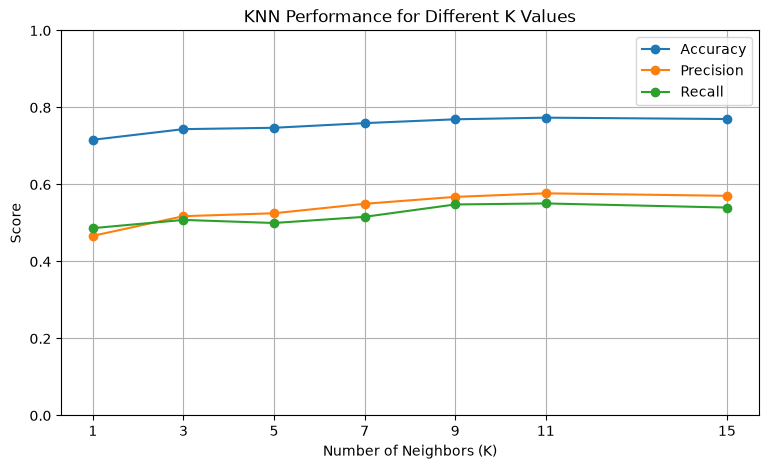

In [30]:
# Plot the performance of each K value
plt.figure(figsize=(9, 5))

plt.plot(
    results_df["K"],
    results_df["Accuracy"],
    marker="o",
    label="Accuracy"
)

plt.plot(
    results_df["K"],
    results_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    results_df["K"],
    results_df["Recall"],
    marker="o",
    label="Recall"
)

plt.title("KNN Performance for Different K Values")
plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Score")
plt.xticks(k_values)
plt.ylim(0, 1)
plt.legend()
plt.grid(True)
plt.show()

In [31]:
# Select the best K value
# Recall is prioritized because detecting potential churners is important
best_result = results_df.sort_values(
    by=["Recall", "Precision", "Accuracy"],
    ascending=False
).iloc[0]

best_k = int(best_result["K"])

print("Best K value:", best_k)
print(f"Accuracy:  {best_result['Accuracy']:.4f}")
print(f"Precision: {best_result['Precision']:.4f}")
print(f"Recall:    {best_result['Recall']:.4f}")

Best K value: 11
Accuracy:  0.7736
Precision: 0.5770
Recall:    0.5508


In [32]:
# ============================================================
# Step 7: Final Model Evaluation
# ============================================================

# Train the final model using the selected K value
final_knn = KNeighborsClassifier(n_neighbors=best_k)

final_knn.fit(X_train_scaled, y_train)

# Make final predictions
final_predictions = final_knn.predict(X_test_scaled)

# Calculate final metrics
final_accuracy = accuracy_score(y_test, final_predictions)
final_precision = precision_score(
    y_test,
    final_predictions,
    zero_division=0
)
final_recall = recall_score(
    y_test,
    final_predictions,
    zero_division=0
)

print(f"Selected K value: {best_k}")
print(f"Accuracy: {final_accuracy:.4f}")
print(f"Precision: {final_precision:.4f}")
print(f"Recall: {final_recall:.4f}")

print("\nFinal classification report:")
print(
    classification_report(
        y_test,
        final_predictions,
        target_names=["No Churn", "Churn"],
        zero_division=0
    )
)

Selected K value: 11
Accuracy: 0.7736
Precision: 0.5770
Recall: 0.5508

Final classification report:
              precision    recall  f1-score   support

    No Churn       0.84      0.85      0.85      1035
       Churn       0.58      0.55      0.56       374

    accuracy                           0.77      1409
   macro avg       0.71      0.70      0.71      1409
weighted avg       0.77      0.77      0.77      1409



In [33]:
# Create a copy for feature analysis
analysis_df = df_processed.copy()
analysis_df["ChurnBinary"] = y


# Compare churn rates for selected categorical features
categorical_features = [
    "Contract",
    "InternetService",
    "PaymentMethod",
    "OnlineSecurity",
    "TechSupport",
    "PaperlessBilling"
]

for feature in categorical_features:
    print(f"\nChurn rate by {feature}:")
    
    churn_rates = (
        analysis_df.groupby(feature)["ChurnBinary"]
        .agg(["mean", "count"])
        .sort_values("mean", ascending=False)
    )
    
    churn_rates["ChurnRatePercentage"] = churn_rates["mean"] * 100
    display(churn_rates)


Churn rate by Contract:


,mean,count,ChurnRatePercentage
Contract,,,
Month-to-month,0.427097,3875,42.709677
One year,0.112695,1473,11.269518
Two year,0.028319,1695,2.831858



Churn rate by InternetService:


,mean,count,ChurnRatePercentage
InternetService,,,
Fiber optic,0.418928,3096,41.892765
DSL,0.189591,2421,18.959108
No,0.074050,1526,7.404980



Churn rate by PaymentMethod:


,mean,count,ChurnRatePercentage
PaymentMethod,,,
Electronic check,0.452854,2365,45.285412
Mailed check,0.191067,1612,19.106700
Bank transfer (automatic),0.167098,1544,16.709845
Credit card (automatic),0.152431,1522,15.243101


... (2 outputs left out)


Churn rate by TechSupport:


,mean,count,ChurnRatePercentage
TechSupport,,,
No,0.416355,3473,41.635474
Yes,0.151663,2044,15.166341
No internet service,0.074050,1526,7.404980



Churn rate by PaperlessBilling:


,mean,count,ChurnRatePercentage
PaperlessBilling,,,
Yes,0.335651,4171,33.565092
No,0.163301,2872,16.330084


In [34]:
# Compare numerical feature averages for customers who stayed and churned
numeric_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

print("Average numerical feature values by churn status:")
display(
    analysis_df.groupby("Churn")[numeric_features].mean()
)

Average numerical feature values by churn status:


,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,37.569965,61.265124,2552.882494
Yes,17.979133,74.441332,1531.796094


## Analysis and Conclusions

The final KNN model achieved an accuracy of approximately [0.7736 — 77.36%]
on the test set. Its precision was approximately [0.5770 — 57.70%], and its
recall was approximately [0.5508 — 55.08%].

Recall is important for this problem because it measures how many customers
who actually churned were identified by the model.

The feature analysis suggests that customers with month-to-month contracts,
higher monthly charges, shorter tenure, electronic payment methods, and
certain internet service types may have higher churn rates. These patterns
should be investigated further before making business decisions.

### Business Recommendations

The telecommunications company could:

- Contact customers identified as high-risk churn customers.
- Offer incentives to month-to-month customers to switch to longer contracts.
- Review pricing and service quality for customers with high monthly charges.
- Provide additional support to newer customers during their first few months.
- Investigate complaints and service issues among internet-service customers
  with high churn rates.
- Use recall as an important performance measure when the cost of losing a
  customer is high.

### Model Limitations

- KNN is sensitive to feature scaling, although scaling was applied.
- The dataset has more non-churning customers than churning customers.
- Accuracy alone may hide poor performance on the churn class.
- The model was evaluated using one train-test split.
- KNN does not provide direct feature-importance values.
- The analysis shows relationships, not proof that a feature causes churn.
- Customer behavior and business conditions may change over time.
- Future work could use cross-validation, hyperparameter tuning, and other
  models such as logistic regression, decision trees, or random forests.